In [29]:
import sys
sys.path.append("../..")

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [31]:
df_ch_przeplyw = pd.read_parquet('../../data/processed/Chorzów/przeplyw.parquet')
df_ch_scieki = pd.read_parquet('../../data/processed/Chorzów/scieki.parquet')
df_ch_awarie = pd.read_parquet('../../data/processed/Chorzów/awarie.parquet')
df_ch_energia = pd.read_parquet('../../data/processed/Chorzów/energia.parquet')
df_ch_opady = pd.read_parquet('../../data/processed/Chorzów/suma_opadow.parquet')

### LightGBM

In [32]:
df = df_ch_energia.copy()

df["Sposób_pomiaru"] = df["Sposób_pomiaru"].astype(str).str.strip()
df = df[df["Sposób_pomiaru"] == "Wartość z pomiaru"].copy()

if "Data_czas" in df.columns:
    df["Data_czas"] = pd.to_datetime(df["Data_czas"])
    df = df.set_index("Data_czas")

df = df.rename(columns={"Zuzycie_energii_elektrycznej": "energia"})

# Konwersja na wartości liczbowe
df["energia"] = pd.to_numeric(
    df["energia"].astype(str).str.replace(",", ".", regex=False),
    errors="coerce"
)

df = df[df["energia"].notna()]
df = df.sort_index()

print(df[["energia"]].head(10))

                     energia
Data_czas                   
2024-10-13 00:00:00   515940
2024-10-13 00:00:54   515940
2024-10-13 00:01:06   515941
2024-10-13 00:01:14   515941
2024-10-13 00:01:18   515941
2024-10-13 00:01:26   515941
2024-10-13 00:01:34   515941
2024-10-13 00:01:52   515941
2024-10-13 00:05:00   515941
2024-10-13 00:10:00   515941


In [33]:
# Usuwamy zduplikowane daty, zachowując największy odczyt licznika energii
df = df.groupby(level=0).agg({"energia": "max"})
df = df.sort_index()

df.head()

,energia
Data_czas,
2024-10-13 00:00:00,515940
2024-10-13 00:00:54,515940
2024-10-13 00:01:06,515941
2024-10-13 00:01:14,515941
2024-10-13 00:01:18,515941


In [34]:
#Godzinowe zużycie energii z licznika narastającego
hourly = df["energia"].resample("1h").last()

df_1h = pd.DataFrame({
    "zuzycie_energii": hourly.diff()
})

# Reset licznika lub nieprawidłowy odczyt
df_1h.loc[df_1h["zuzycie_energii"] < 0, "zuzycie_energii"] = np.nan

df_lgbm = df_1h.join(
    df_ch_opady[["suma_opadu_mm"]],
    how="left"
)

print(df_lgbm.head(10))

                     zuzycie_energii  suma_opadu_mm
Data_czas                                          
2024-10-13 00:00:00              NaN            NaN
2024-10-13 01:00:00              3.0            NaN
2024-10-13 02:00:00              2.0            NaN
2024-10-13 03:00:00              3.0            NaN
2024-10-13 04:00:00              2.0            NaN
2024-10-13 05:00:00              3.0            NaN
2024-10-13 06:00:00              2.0            NaN
2024-10-13 07:00:00              3.0            NaN
2024-10-13 08:00:00              3.0            NaN
2024-10-13 09:00:00              4.0            NaN


In [35]:
#Kontekst kalendarzowy dla prognozowania zużycia energii
df_lgbm["hour"] = df_lgbm.index.hour
df_lgbm["dayofweek"] = df_lgbm.index.day_of_week
df_lgbm["month"] = df_lgbm.index.month
df_lgbm["weekend"] = (df_lgbm["dayofweek"] >= 5).astype(int)

print(df_lgbm.head(10))

                     zuzycie_energii  suma_opadu_mm  hour  dayofweek  month  \
Data_czas                                                                     
2024-10-13 00:00:00              NaN            NaN     0          6     10   
2024-10-13 01:00:00              3.0            NaN     1          6     10   
2024-10-13 02:00:00              2.0            NaN     2          6     10   
2024-10-13 03:00:00              3.0            NaN     3          6     10   
2024-10-13 04:00:00              2.0            NaN     4          6     10   
2024-10-13 05:00:00              3.0            NaN     5          6     10   
2024-10-13 06:00:00              2.0            NaN     6          6     10   
2024-10-13 07:00:00              3.0            NaN     7          6     10   
2024-10-13 08:00:00              3.0            NaN     8          6     10   
2024-10-13 09:00:00              4.0            NaN     9          6     10   

                     weekend  
Data_czas           

In [36]:
r = df_lgbm["suma_opadu_mm"]

# Opady z poprzednich godzin
for k in [1, 2, 3, 6, 12, 24, 48, 72, 168]:
    df_lgbm[f"opad_{k}h"] = r.shift(1).rolling(k).sum()

df_lgbm["opad_max3h"] = r.shift(1).rolling(3).max()

last_rain = df_lgbm.index.to_series().where(r.shift(1) > 0.1).ffill()

df_lgbm["h_od_deszczu"] = (
    (df_lgbm.index.to_series() - last_rain)
    .dt.total_seconds() / 3600
).clip(upper=240)

print(df_lgbm.head())

                     zuzycie_energii  suma_opadu_mm  hour  dayofweek  month  \
Data_czas                                                                     
2024-10-13 00:00:00              NaN            NaN     0          6     10   
2024-10-13 01:00:00              3.0            NaN     1          6     10   
2024-10-13 02:00:00              2.0            NaN     2          6     10   
2024-10-13 03:00:00              3.0            NaN     3          6     10   
2024-10-13 04:00:00              2.0            NaN     4          6     10   

                     weekend  opad_1h  opad_2h  opad_3h  opad_6h  opad_12h  \
Data_czas                                                                    
2024-10-13 00:00:00        1      NaN      NaN      NaN      NaN       NaN   
2024-10-13 01:00:00        1      NaN      NaN      NaN      NaN       NaN   
2024-10-13 02:00:00        1      NaN      NaN      NaN      NaN       NaN   
2024-10-13 03:00:00        1      NaN      NaN      NaN 

In [37]:
energia = df_lgbm["zuzycie_energii"]

for k in [1, 3, 6, 24, 168]:
    df_lgbm[f"energia_lag_{k}h"] = energia.shift(k)

df_lgbm["energia_mean_6h"] = energia.shift(1).rolling(6).mean()
df_lgbm["energia_mean_24h"] = energia.shift(1).rolling(24).mean()

In [38]:
features = [
    "hour", "dayofweek", "month", "weekend",
    "opad_1h", "opad_3h", "opad_6h", "opad_12h",
    "opad_24h", "opad_48h", "opad_72h", "opad_168h",
    "opad_max3h", "h_od_deszczu",
    "energia_lag_1h", "energia_lag_3h", "energia_lag_6h",
    "energia_lag_24h", "energia_lag_168h",
    "energia_mean_6h", "energia_mean_24h"
]

X = df_lgbm[features].copy()
y = df_lgbm["zuzycie_energii"].copy()

print("Liczba cech:", X.shape[1])
print("Liczba obserwacji:", len(X))

print("\nBraki w cechach:", X.isna().sum())
print("\nBraki w y:", y.isna().sum())

Liczba cech: 21
Liczba obserwacji: 17521

Braki w cechach: hour                    0
dayofweek               0
month                   0
weekend                 0
opad_1h             17521
opad_3h             17521
opad_6h             17521
opad_12h            17521
opad_24h            17521
opad_48h            17521
opad_72h            17521
opad_168h           17521
opad_max3h          17521
h_od_deszczu        17521
energia_lag_1h          6
energia_lag_3h          8
energia_lag_6h         11
energia_lag_24h        29
energia_lag_168h      173
energia_mean_6h        21
energia_mean_24h       75
dtype: int64

Braki w y: 5


In [39]:
# Usuwamy tylko wiersze z brakującą wartością docelową
valid_idx = y.notna()

X = X.loc[valid_idx].copy()
y = y.loc[valid_idx].copy()

train_end = int(len(X)*0.7)
val_end = int(len(X)*0.85)

X_train = X.iloc[:train_end]
X_val = X.iloc[train_end:val_end]
X_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

print("TRAIN:", X_train.shape, X_train.index.min(), X_train.index.max())
print("VAL:", X_val.shape, X_val.index.min(), X_val.index.max())
print("TEST:", X_test.shape, X_test.index.min(), X_test.index.max())

TRAIN: (12261, 21) 2024-10-13 01:00:00 2026-03-07 23:00:00
VAL: (2627, 21) 2026-03-08 00:00:00 2026-06-25 12:00:00
TEST: (2628, 21) 2026-06-25 13:00:00 2026-10-13 00:00:00


In [40]:
lgbm = LGBMRegressor( objective="regression", n_estimators=300, learning_rate=0.05, num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm.fit(X_train, y_train)



lgbm_q = LGBMRegressor(objective="quantile", alpha=0.97, n_estimators=300, learning_rate=0.05,
                       num_leaves=15, min_child_samples=40, random_state=42, verbosity=-1)

lgbm_q.fit(X_train, y_train)

,num_leaves,15
,learning_rate,0.05
,n_estimators,300
,objective,'quantile'
,min_child_samples,40
,random_state,42
,alpha,0.97
,verbosity,-1
,boosting_type,'gbdt'
,max_depth,-1
,subsample_for_bin,200000


In [41]:
# Prognoza zużycia energii na walidacji
y_pred_val = lgbm.predict(X_val)
q_val = lgbm_q.predict(X_val)


# Baseline - mediana zużycia energii dla danej godziny
prof = y_train.groupby(y_train.index.hour).median()
base_val = prof.reindex(y_val.index.hour).values

print("MAE LightGBM:", round(mean_absolute_error(y_val, y_pred_val), 2))
print("MAE baseline:", round(mean_absolute_error(y_val, base_val), 2))

print("RMSE LightGBM:", round(np.sqrt(mean_squared_error(y_val, y_pred_val)), 2))
print("RMSE baseline:", round(np.sqrt(mean_squared_error(y_val, base_val)), 2))

MAE LightGBM: 1.18
MAE baseline: 1.4
RMSE LightGBM: 3.22
RMSE baseline: 4.83


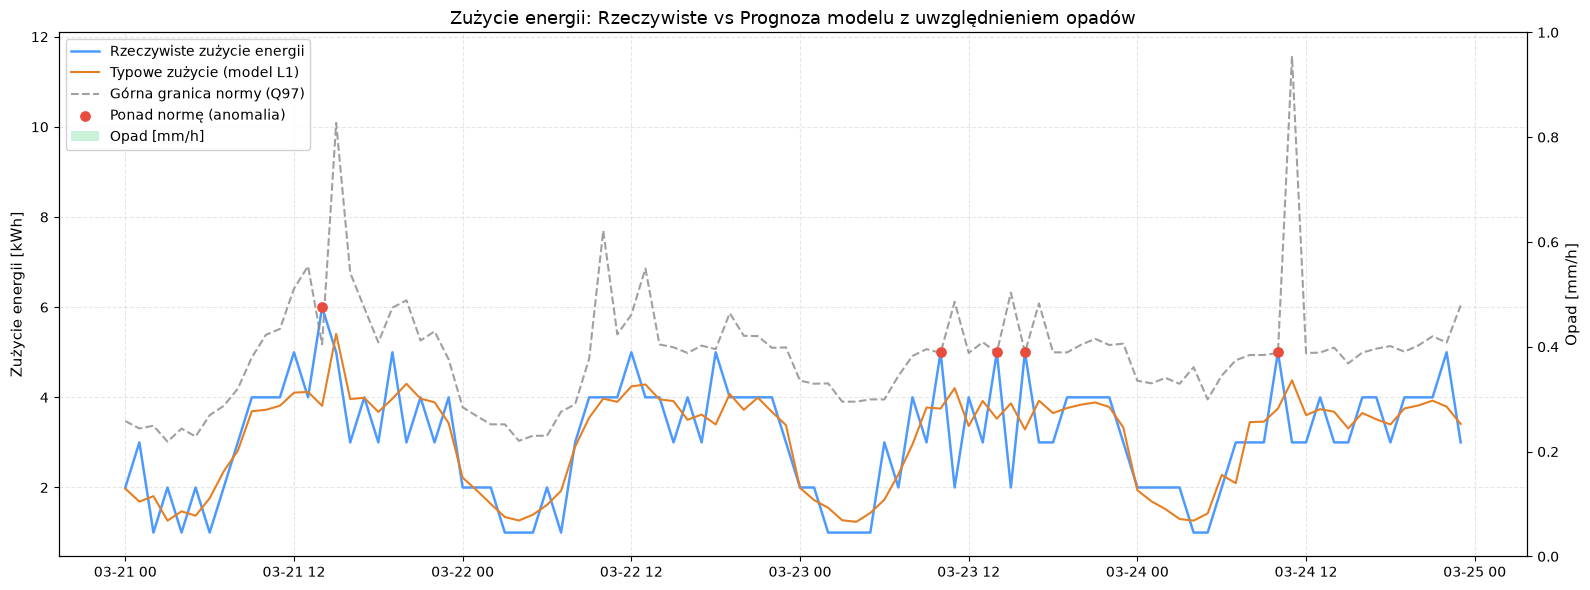

In [42]:
results_val = pd.DataFrame(
    {
        "rzeczywiste": y_val,
        "prognoza": y_pred_val,
        "q97": q_val,
        "opad": X_val["opad_1h"],
    },
    index=y_val.index,
)

sample = results_val.loc["2026-03-21":"2026-03-24"]

# punkty ponad normę
anomalie = sample[sample["rzeczywiste"] > sample["q97"]]

fig, ax1 = plt.subplots(figsize=(16, 6))

# Oś 1: Zużycie energii
ax1.plot(
    sample.index,
    sample["rzeczywiste"],
    label="Rzeczywiste zużycie energii",
    color="#4C9AFF",
    linewidth=1.8,
)
ax1.plot(
    sample.index,
    sample["prognoza"],
    label="Typowe zużycie (model L1)",
    color="#E67E22",
    linewidth=1.5,
)
if "q97" in sample.columns:
  ax1.plot(
      sample.index,
      sample["q97"],
      label="Górna granica normy (Q97)",
      color="#888888",
      linestyle="--",
      alpha=0.8,
  )
  if len(anomalie) > 0:
    ax1.scatter(
        anomalie.index,
        anomalie["rzeczywiste"],
        color="#E74C3C",
        s=45,
        zorder=5,
        label="Ponad normę (anomalia)",
    )

ax1.set_ylabel("Zużycie energii [kWh]", fontsize=11)
ax1.set_title(
    "Zużycie energii: Rzeczywiste vs Prognoza modelu z uwzględnieniem opadów",
    fontsize=13,
)
ax1.grid(True, linestyle="--", alpha=0.3)

# Oś 2: Słupki opadów deszczu w tle
ax2 = ax1.twinx()
ax2.bar(
    sample.index,
    sample["opad"],
    width=0.03,
    color="#2ECC71",
    alpha=0.25,
    label="Opad [mm/h]",
)
ax2.set_ylabel("Opad [mm/h]", fontsize=11)
max_opad = sample["opad"].dropna().max() if not sample["opad"].dropna().empty else 0
ax2.set_ylim(0, max(max_opad * 4, 1.0))

# Połączenie legend z obu osi w jedno okno
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", framealpha=0.9)

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()